# 3 — Viscosity inversion at a matched parameter budget

Example 3 of the manuscript. Velocities generated from
$K^*(s)=0.08+1.6s(1-s)^2$ by independent collocation, with complex Gaussian
noise rescaled to 1% of the velocity norm, are inverted for $K$ by
reverse-mode automatic differentiation and bounded L-BFGS. Only the noisy
velocities enter the loss; $K^*$ is used solely to score the result.

Interpolation degrees 0, 1 and 2 are compared at **eleven parameters each**,
the layer count absorbing the difference. Without that matching the
comparison is meaningless: a degree-2 model on ten layers carries twenty-one
parameters and simply overfits the noise.

In [1]:
using Pkg
Pkg.activate(joinpath(@__DIR__, ".."))
using ELES, LinearAlgebra, Printf
ENV["GKSwstype"] = "100"
using Plots
default(frame = :box, grid = false, size = (820, 300),
        lw = 2, legendfontsize = 7, titlefontsize = 9, guidefontsize = 8)
include(joinpath(@__DIR__, "..", "examples", "reference_shooting.jl"))
println("layer kinds: ", LAYER_KINDS)
using DelimitedFiles

layer kinds: (:constant, :linear, :quadratic, :exponential)


  Activating project at `<package>`


In [2]:
data = readdlm(joinpath(@__DIR__, "..", "data", "synthetic_velocity.csv"),
                ',', Float64; skipstart = 1)
z = data[:, 1]; Ktrue = data[:, 2]
clean = data[:, 3] .+ 1im .* data[:, 4]
observed = data[:, 5] .+ 1im .* data[:, 6]
@printf("%d observations, relative noise %.4f\n", length(z),
        norm(observed - clean)/norm(clean))

161 observations, relative noise 0.0100


In [3]:
BUDGET = 11
LAYERS = Dict(:constant => BUDGET, :linear => BUDGET - 1,
              :quadratic => (BUDGET - 1) ÷ 2)

"""Heights whose viscosity values the parameters are, in parameter order."""
function nodes(model)
    out = zeros(model.nparameters)
    for k in eachindex(model.kinds)
        lo, hi = model.interfaces[k], model.interfaces[k+1]
        if model.kinds[k] == :constant
            out[model.left_index[k]] = (lo + hi)/2
        else
            out[model.left_index[k]] = lo
            out[model.right_index[k]] = hi
            model.mid_index[k] == 0 || (out[model.mid_index[k]] = (lo + hi)/2)
        end
    end
    out
end

In [4]:
using Zygote
results = Dict()
@printf("%-10s %6s %7s %10s %12s %10s\n",
        "degree", "layers", "params", "E_K", "loss", "AD vs FD")
for (d, kind) in enumerate((:constant, :linear, :quadratic))
    model = LayerModel(collect(range(0, 1, length = LAYERS[kind] + 1)); kind)
    @assert model.nparameters == BUDGET
    initial = 0.085 .+ 0.94 .* nodes(model) .* (1 .- nodes(model))
    theta = log.(initial)
    loss(t) = sum(abs2, ekman_forward(model, exp.(t), z) .- observed)/length(z)
    ad = Zygote.gradient(loss, theta)[1]
    best = minimum(map((1e-4, 1e-5, 1e-6, 1e-7)) do hh
        fd = [(loss(theta + [i == j ? hh : 0.0 for i in eachindex(theta)]) -
               loss(theta - [i == j ? hh : 0.0 for i in eachindex(theta)]))/(2hh)
              for j in eachindex(theta)]
        norm(ad - fd)/norm(ad)
    end)
    fit = fit_viscosity(model, z, observed; initial, lower = 0.06, upper = 0.50)
    Kfit = viscosity(solve_layered(model, fit.values, 1im, -1.0im, 0.0im), z)
    EK = norm(Kfit - Ktrue)/norm(Ktrue)
    results[kind] = (Kfit, fit, EK)
    @printf("%-10d %6d %7d %9.4f%% %12.3e %10.1e\n",
            d - 1, LAYERS[kind], model.nparameters, 100EK, fit.loss, best)
end

degree     layers  params        E_K         loss   AD vs FD
0              11      11    9.6794%    6.246e-05    8.8e-11
1              10      11    1.4479%    3.031e-05    2.1e-10
2               5      11    1.1675%    3.015e-05    1.0e-10


The recovery improves with the degree. Degrees 1 and 2 fit the
data almost identically — at 1% noise their losses are indistinguishable — yet
the degree-2 viscosity is noticeably closer to the truth. The extra order buys
accuracy in $K$ that the velocity residual cannot see.

## Local Gaussian uncertainty
The three panels reproduce the conditional 95% intervals, the uncertainty in K(0.5+) with the right-layer convention, and the observations/fits. A fixed seed generates 20,000 local Gauss–Newton draws per model. Representation bias is excluded; these are not full nonlinear posterior intervals.


constant: Jacobian rank 11, draws in box 100.0%, admissible 100.0%
linear: Jacobian rank 11, draws in box 100.0%, admissible 100.0%
quadratic: Jacobian rank 11, draws in box 100.0%, admissible 100.0%


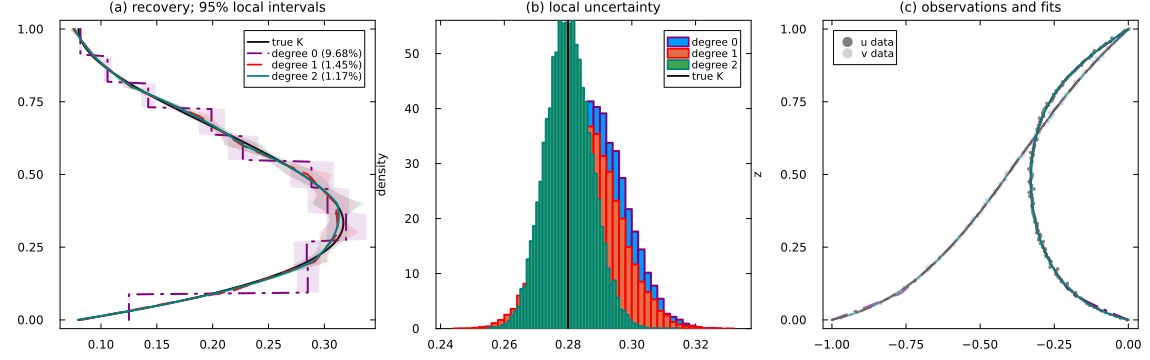

In [5]:
include(joinpath(@__DIR__, "..", "examples", "paper_reproduction.jl"))
using .PaperReproduction
figure, intervals = inversion_figure(data, results)
for kind in (:constant, :linear, :quadratic)
    u = intervals[kind]
    @printf("%s: Jacobian rank %d, draws in box %.1f%%, admissible %.1f%%\n",
            kind, u.rank, 100u.fraction_in_box, 100u.fraction_admissible)
end
figure
